# 09 — Predictive Utility (TSTR)

**Capstone:** Comparative Evaluation of Diffusion, GAN, and VAE Models for Synthetic Clinical Tabular Data Generation.

**Purpose:** Train one fixed prediction model on each synthetic dataset (**TSTR: Train on Synthetic, Test on Real**) and compare it with a **TRTR: Train on Real, Test on Real** baseline. Every model is evaluated **only on the same patient-disjoint real test partition**. No model generation or tuning happens here.

This notebook uses *Logistic Regression* as a transparent first predictive-utility benchmark. For minority-class preservation it reports AUROC, average precision (AUPRC), recall, precision, F1, balanced accuracy, and Brier score. It does **not** treat matching label prevalence as proof of utility. No model hyperparameters or thresholds are selected using the held-out test set.

## 1. Imports and paths
Select the project `.venv` kernel. If run in `notebooks/`, paths resolve automatically.

In [1]:
from pathlib import Path
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, balanced_accuracy_score,
                             brier_score_loss, confusion_matrix,
                             precision_recall_curve, roc_curve)

SEED = 42
ROOT = Path.cwd().resolve()
if not (ROOT / "data/processed/train_semantic.csv").exists():
    ROOT = ROOT.parent
assert (ROOT / "data/processed/train_semantic.csv").exists(), f"Cannot find project root from {Path.cwd()}"
OUT = ROOT / "results/utility"
OUT.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = ROOT / "data/processed/train_semantic.csv"
TEST_PATH = ROOT / "data/processed/test_semantic.csv"
META_PATH = ROOT / "data/processed/preprocessing_metadata.json"
SYN_PATHS = {
    "TVAE 50": ROOT / "data/synthetic/tvae_50ep.csv",
    "TVAE 300": ROOT / "data/synthetic/tvae_300ep.csv",
    "CTGAN 300": ROOT / "data/synthetic/ctgan_300ep.csv",
    "TabDDPM 100": ROOT / "data/synthetic/tabddpm_joint_100ep.csv",
}
print("Project:", ROOT)
print("Utility results:", OUT.relative_to(ROOT))

Project: /home/ayanasanthosh.ds25a/synthetic-clinical-data-generation
Utility results: results/utility


## 2. Load train, synthetic and held-out test datasets
The test partition remains reserved for **evaluation only**. Its labels must never be used to train models, choose hyperparameters or tune the classification threshold.

In [2]:
with open(META_PATH, encoding="utf-8") as f:
    meta = json.load(f)
NUM = list(meta["numerical_feature_columns"])
CAT = list(meta["categorical_feature_columns"])
TARGET = meta["target_column"]
FEATURES = NUM + CAT
assert TARGET == "readmitted_30" and len(NUM) == 8 and len(CAT) == 36

real_train = pd.read_csv(TRAIN_PATH)
real_test = pd.read_csv(TEST_PATH)
synth = {name: pd.read_csv(p) for name, p in SYN_PATHS.items()}

for name, df in [("Real training", real_train), ("Real held-out test", real_test)] + list(synth.items()):
    assert set(FEATURES + [TARGET]) == set(df.columns), f"{name}: mismatched columns"
    assert df[TARGET].notna().all(), f"{name}: missing target labels"
    assert set(pd.to_numeric(df[TARGET]).unique()).issubset({0, 1}), f"{name}: invalid targets"

assert real_train.shape == (79567, 45) and real_test.shape == (19773, 45)
assert all(df.shape == real_train.shape for df in synth.values())

def label_counts(df):
    y = pd.to_numeric(df[TARGET]).astype(int)
    return int(y.sum()), float(y.mean())

summary = []
for name, df in [("Real training", real_train), ("Real held-out test", real_test)] + list(synth.items()):
    pos, rate = label_counts(df)
    summary.append({"dataset": name, "rows": len(df), "columns": len(df.columns),
                    "positives": pos, "positive_pct": round(100 * rate, 3)})
shape_summary = pd.DataFrame(summary)
display(shape_summary)
print("Features:", len(NUM), "numerical +", len(CAT), "categorical")
print("The real test partition is never used for fitting.")

,dataset,rows,columns,positives,positive_pct
0,Real training,79567,45,9070,11.399
1,Real held-out test,19773,45,2244,11.349
2,TVAE 50,79567,45,0,0.000
3,TVAE 300,79567,45,34,0.043
4,CTGAN 300,79567,45,3279,4.121
5,TabDDPM 100,79567,45,8407,10.566


Features: 8 numerical + 36 categorical
The real test partition is never used for fitting.


## 3. Fixed predictor and evaluation functions
The same algorithm, hyperparameters and 0.5 threshold are used for each training source. Categorical columns—including numeric-looking admission codes—are one-hot encoded; encoding and numeric scaling are **fitted separately on each training source**, never on the real test set.

**Zero-positive TVAE 50:** Logistic regression cannot learn both classes from that dataset. A deterministic all-negative fallback is shown and clearly labelled *single-class fallback*, not a successful trained classifier.

In [3]:
def prepare_x(df):
    x = df[FEATURES].copy()
    for col in NUM:
        x[col] = pd.to_numeric(x[col], errors="coerce")
        x[col] = x[col].replace([np.inf, -np.inf], np.nan)
    for col in CAT:
        x[col] = x[col].astype("string").fillna("__MISSING__").astype(str)
    return x


def make_model():
    transformer = ColumnTransformer([
        ("numeric", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), NUM),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), CAT),
    ], remainder="drop")
    classifier = LogisticRegression(
        solver="liblinear", max_iter=1500, C=1.0,
        class_weight="balanced", random_state=SEED
    )
    return Pipeline([("preprocessing", transformer), ("predictor", classifier)])


def run_one(name, train_df, test_df):
    xtrain, x_test = prepare_x(train_df), prepare_x(test_df)
    ytrain = pd.to_numeric(train_df[TARGET]).astype(int).to_numpy()
    ytest = pd.to_numeric(test_df[TARGET]).astype(int).to_numpy()
    started = time.perf_counter()

    if len(np.unique(ytrain)) < 2:
        # Explicitly report that the training source contains only one class.
        model = DummyClassifier(strategy="most_frequent")
        model.fit(np.zeros((len(ytrain), 1)), ytrain)
        score = np.full(len(ytest), float(ytrain[0]))
        model_status = "single-class fallback (not logistic regression)"
    else:
        model = make_model()
        model.fit(xtrain, ytrain)
        score = model.predict_proba(x_test)[:, 1]
        model_status = "logistic regression fitted"

    pred = (score >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(ytest, pred, labels=[0, 1]).ravel()
    metrics = {
        "train_source": name,
        "train_rows": len(train_df),
        "train_positives": int(ytrain.sum()),
        "model_status": model_status,
        "auroc": roc_auc_score(ytest, score),
        "average_precision": average_precision_score(ytest, score),
        "balanced_accuracy": balanced_accuracy_score(ytest, pred),
        "precision": precision_score(ytest, pred, zero_division=0),
        "recall": recall_score(ytest, pred, zero_division=0),
        "f1": f1_score(ytest, pred, zero_division=0),
        "brier": brier_score_loss(ytest, score),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "fit_and_eval_seconds": round(time.perf_counter() - started, 1),
    }
    return metrics, score

print("Predictor: LogisticRegression(C=1.0, class_weight='balanced', solver='liblinear')")
print("Classification threshold: 0.5 | Positive class: readmitted_30 = 1")

Predictor: LogisticRegression(C=1.0, class_weight='balanced', solver='liblinear')
Classification threshold: 0.5 | Positive class: readmitted_30 = 1


## 4. Train on real/synthetic; test on held-out real
This is the main TSTR evaluation. All five models use **identical test records**. The real-trained predictor is the TRTR reference, not a perfect-performance target.

In [4]:
train_sources = {"TRTR (Real train)": real_train, **synth}
metric_rows = []
score_by_source = {}
for name, train_df in train_sources.items():
    print("Fitting/evaluating:", name, flush=True)
    m, scores = run_one(name, train_df, real_test)
    metric_rows.append(m)
    score_by_source[name] = scores
    print(f"  AUROC={m['auroc']:.4f}  AP={m['average_precision']:.4f}  "
          f"F1={m['f1']:.4f}  Recall={m['recall']:.4f}  "
          f"({m['fit_and_eval_seconds']}s)", flush=True)

utility = pd.DataFrame(metric_rows).set_index("train_source")
display(utility[["model_status", "train_positives", "auroc", "average_precision",
                 "precision", "recall", "f1", "balanced_accuracy", "brier"]].round(4))

utility.to_csv(OUT / "tstr_logreg_results.csv")
print("Saved:", OUT / "tstr_logreg_results.csv")

Fitting/evaluating: TRTR (Real train)
  AUROC=0.6709  AP=0.2264  F1=0.2757  Recall=0.5557  (16.1s)
Fitting/evaluating: TVAE 50
  AUROC=0.5000  AP=0.1135  F1=0.0000  Recall=0.0000  (0.0s)
Fitting/evaluating: TVAE 300
  AUROC=0.6007  AP=0.1735  F1=0.1223  Recall=0.0775  (5.9s)
Fitting/evaluating: CTGAN 300
  AUROC=0.4966  AP=0.1128  F1=0.1738  Recall=0.4073  (16.2s)
Fitting/evaluating: TabDDPM 100
  AUROC=0.6467  AP=0.2095  F1=0.2644  Recall=0.5499  (16.3s)


,model_status,train_positives,auroc,average_precision,precision,recall,f1,balanced_accuracy,brier
train_source,,,,,,,,,
TRTR (Real train),logistic regression fitted,9070,0.6709,0.2264,0.1833,0.5557,0.2757,0.6194,0.2243
TVAE 50,single-class fallback (not logistic regression),0,0.5000,0.1135,0.0000,0.0000,0.0000,0.5000,0.1135
TVAE 300,logistic regression fitted,34,0.6007,0.1735,0.2895,0.0775,0.1223,0.5266,0.1223
CTGAN 300,logistic regression fitted,3279,0.4966,0.1128,0.1105,0.4073,0.1738,0.4937,0.2582
TabDDPM 100,logistic regression fitted,8407,0.6467,0.2095,0.1740,0.5499,0.2644,0.6079,0.2267


Saved: /home/ayanasanthosh.ds25a/synthetic-clinical-data-generation/results/utility/tstr_logreg_results.csv


## 5. Precision–recall and ROC curves
Because 30-day readmission is a minority outcome, **average precision** and the PR curves are important alongside ROC-AUC. The horizontal PR reference equals real test prevalence; a constant prediction cannot recover meaningful discrimination.

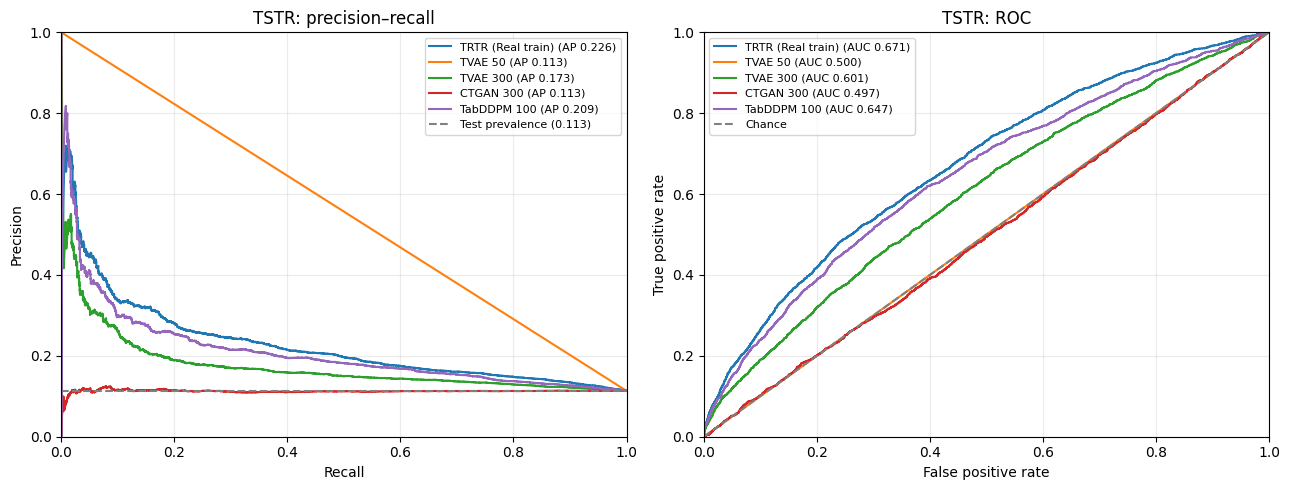

Saved: /home/ayanasanthosh.ds25a/synthetic-clinical-data-generation/results/utility/tstr_logreg_pr_roc.png


In [5]:
y_test = pd.to_numeric(real_test[TARGET]).astype(int).to_numpy()
base_rate = float(y_test.mean())
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, scores in score_by_source.items():
    prec, rec, _ = precision_recall_curve(y_test, scores)
    axes[0].plot(rec, prec, label=f"{name} (AP {average_precision_score(y_test, scores):.3f})")
    fpr, tpr, _ = roc_curve(y_test, scores)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, scores):.3f})")
axes[0].axhline(base_rate, color="gray", linestyle="--", label=f"Test prevalence ({base_rate:.3f})")
axes[0].set(xlabel="Recall", ylabel="Precision", title="TSTR: precision–recall", xlim=(0, 1), ylim=(0, 1))
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Chance")
axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="TSTR: ROC", xlim=(0, 1), ylim=(0, 1))
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "tstr_logreg_pr_roc.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", OUT / "tstr_logreg_pr_roc.png")

## 6. Utility relative to real-trained reference
Report absolute TSTR performance and its difference from TRTR. Negative gaps mean a lower score than real-trained baseline. **Do not select the winner on test data and then use the same test data for tuning**.

In [6]:
ref = utility.loc["TRTR (Real train)"]
compare = utility.loc[["TVAE 50", "TVAE 300", "CTGAN 300", "TabDDPM 100"],
                      ["auroc", "average_precision", "recall", "f1"]].copy()
for col in ["auroc", "average_precision", "recall", "f1"]:
    compare[col + "_gap_vs_trtr"] = compare[col] - float(ref[col])
display(compare.round(4))
compare.to_csv(OUT / "tstr_logreg_vs_trtr_gaps.csv")

print("\nInterpretation reminders:")
print("- TVAE 50 had no positive training labels, so its result is a single-class fallback.")
print("- Larger AUROC and average precision generally indicate better discrimination.")
print("- F1/recall depend on the fixed 0.5 threshold and chosen class weighting.")
print("- These results do not establish clinical safety or privacy protection.")
print("- The held-out test set was used only for evaluation.")

,auroc,average_precision,recall,f1,auroc_gap_vs_trtr,average_precision_gap_vs_trtr,recall_gap_vs_trtr,f1_gap_vs_trtr
train_source,,,,,,,,
TVAE 50,0.5000,0.1135,0.0000,0.0000,-0.1709,-0.1129,-0.5557,-0.2757
TVAE 300,0.6007,0.1735,0.0775,0.1223,-0.0701,-0.0529,-0.4782,-0.1534
CTGAN 300,0.4966,0.1128,0.4073,0.1738,-0.1743,-0.1136,-0.1484,-0.1019
TabDDPM 100,0.6467,0.2095,0.5499,0.2644,-0.0241,-0.0169,-0.0058,-0.0113



Interpretation reminders:
- TVAE 50 had no positive training labels, so its result is a single-class fallback.
- Larger AUROC and average precision generally indicate better discrimination.
- F1/recall depend on the fixed 0.5 threshold and chosen class weighting.
- These results do not establish clinical safety or privacy protection.
- The held-out test set was used only for evaluation.


## Capstone reporting notes

- The same patient-disjoint real test set is used throughout (19,773 records, 2,244 positives).
- A consistent **algorithm and fixed settings** are used for all training datasets. Encoding/imputation are fitted on the respective training source, not the held-out test set.
- **TVAE 50** lacks a positive class; its fallback should be called out rather than treated as a successful predictive model.
- TSTR utility must be interpreted together with statistical fidelity and privacy evaluation. **Do not claim TabDDPM is best overall solely from its fidelity scores.**
- The current TabDDPM implementation is *TabDDPM-inspired* and not an exact reproduction of official TabDDPM code.
- Next: privacy-risk assessment (duplicate/nearest-neighbor distances and membership-inference-style auditing, with explicit limitations).